In [1]:
import sys

print(sys.executable)
print(sys.version)

C:\Users\ADMIN\miniconda3\envs\blastoid\python.exe
3.11.16 | packaged by conda-forge | (main, Sep  2 2026, 23:31:17) [MSC v.1944 64 bit (AMD64)]


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)

NumPy: 2.4.6
Pandas: 2.3.3


In [3]:
import numpy as np

expression = np.array([
    [10, 0, 5, 2],
    [0, 15, 2, 8],
    [3, 1, 20, 0]
])

print(expression)

[[10  0  5  2]
 [ 0 15  2  8]
 [ 3  1 20  0]]


In [4]:
print(expression.shape)

(3, 4)


In [5]:
print(expression[:, 0])

[10  0  3]


In [6]:
print(expression[0, :])

[10  0  5  2]


In [7]:
genes = ["NANOG", "SOX2", "POU5F1", "GATA3"]
cells = ["Cell_1", "Cell_2", "Cell_3"]

expression_df = pd.DataFrame(
    expression,
    index=cells,
    columns=genes
)

expression_df

,NANOG,SOX2,POU5F1,GATA3
Cell_1,10,0,5,2
Cell_2,0,15,2,8
Cell_3,3,1,20,0


In [8]:
expression_df.loc["Cell_1"]

NANOG     10
SOX2       0
POU5F1     5
GATA3      2
Name: Cell_1, dtype: int64

In [9]:
expression_df.loc["Cell_2", "SOX2"]

np.int64(15)

In [10]:
expression_df[expression_df["NANOG"] > 2]

,NANOG,SOX2,POU5F1,GATA3
Cell_1,10,0,5,2
Cell_3,3,1,20,0


In [11]:
expression_df.mean()

NANOG     4.333333
SOX2      5.333333
POU5F1    9.000000
GATA3     3.333333
dtype: float64

In [12]:
expression_df.mean(axis=1)

Cell_1    4.25
Cell_2    6.25
Cell_3    6.00
dtype: float64

In [13]:
expression_df["SOX2"]

Cell_1     0
Cell_2    15
Cell_3     1
Name: SOX2, dtype: int64

In [14]:
expression_df.sum(axis=1)

Cell_1    17
Cell_2    25
Cell_3    24
dtype: int64

In [15]:
expression_df[expression_df["NANOG"] > 2]

,NANOG,SOX2,POU5F1,GATA3
Cell_1,10,0,5,2
Cell_3,3,1,20,0


In [16]:
expression_df["NANOG"]

Cell_1    10
Cell_2     0
Cell_3     3
Name: NANOG, dtype: int64

In [17]:
expression_df["NANOG"] > 2

Cell_1     True
Cell_2    False
Cell_3     True
Name: NANOG, dtype: bool

In [18]:
expression_df.loc["Cell_2", "SOX2"]

np.int64(15)

In [19]:
expression_df.iloc[1, 1]

np.int64(15)

In [20]:
expression_df.loc[expression_df["POU5F1"] > 10]

,NANOG,SOX2,POU5F1,GATA3
Cell_3,3,1,20,0


In [21]:
import numpy as np
import pandas as pd

In [22]:
expression = np.array([
    [10, 0, 5, 2],
    [0, 15, 2, 8],
    [3, 1, 20, 0]
])

In [23]:
genes = ["NANOG", "SOX2", "POU5F1", "GATA3"]
cells = ["Cell_1", "Cell_2", "Cell_3"]

expression_df = pd.DataFrame(
    expression,
    index=cells,
    columns=genes
)

expression_df

,NANOG,SOX2,POU5F1,GATA3
Cell_1,10,0,5,2
Cell_2,0,15,2,8
Cell_3,3,1,20,0


In [24]:
expression_df.mean().idxmax()

'POU5F1'

In [25]:
expression_df.sum(axis=1).idxmax()

'Cell_2'

In [26]:
expression_df.sum().idxmax()

'POU5F1'

In [27]:
expression_df.loc[expression_df["GATA3"] > 5]

,NANOG,SOX2,POU5F1,GATA3
Cell_2,0,15,2,8


In [28]:
expression_df[expression_df["GATA3"] > 5]

,NANOG,SOX2,POU5F1,GATA3
Cell_2,0,15,2,8


In [29]:
import matplotlib.pyplot as plt

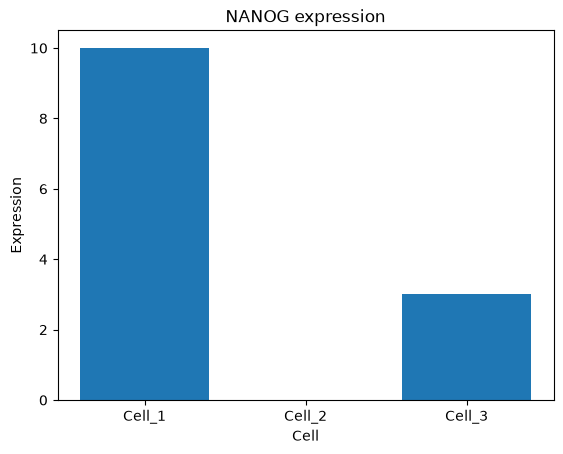

In [30]:
import matplotlib.pyplot as plt

plt.bar(
    expression_df.index,
    expression_df["NANOG"]
)

plt.xlabel("Cell")
plt.ylabel("Expression")
plt.title("NANOG expression")
plt.show()

In [31]:
expression_df.std()

NANOG     5.131601
SOX2      8.386497
POU5F1    9.643651
GATA3     4.163332
dtype: float64

In [32]:
import scanpy as sc

In [33]:
adata = sc.AnnData(expression_df)

In [34]:
adata

AnnData object with n_obs × n_vars = 3 × 4

In [35]:
adata.X

array([[10,  0,  5,  2],
       [ 0, 15,  2,  8],
       [ 3,  1, 20,  0]])

In [36]:
adata.obs

""
Cell_1
Cell_2
Cell_3


In [37]:
adata.obs["stage"] = ["D7", "D7", "D14"]

In [38]:
adata.obs

,stage
Cell_1,D7
Cell_2,D7
Cell_3,D14


In [39]:
adata.obs["stage"] == "D7"

Cell_1     True
Cell_2     True
Cell_3    False
Name: stage, dtype: bool

In [40]:
adata.var

""
NANOG
SOX2
POU5F1
GATA3


In [41]:
adata.var["gene_type"] = [
    "protein_coding",
    "protein_coding",
    "protein_coding",
    "protein_coding"
]

In [42]:
adata.var

,gene_type
NANOG,protein_coding
SOX2,protein_coding
POU5F1,protein_coding
GATA3,protein_coding


In [43]:
adata[["Cell_1"]]

View of AnnData object with n_obs × n_vars = 1 × 4
    obs: 'stage'
    var: 'gene_type'

In [44]:
adata["Cell_1"]

View of AnnData object with n_obs × n_vars = 1 × 4
    obs: 'stage'
    var: 'gene_type'

In [45]:
adata_d7 = adata[adata.obs["stage"] == "D7"]

In [46]:
adata[:, adata.var["gene_type"] == "protein_coding"]

View of AnnData object with n_obs × n_vars = 3 × 4
    obs: 'stage'
    var: 'gene_type'

In [47]:
adata_d7 = adata[adata.obs["stage"] == "D7"].copy()

In [48]:
adata[adata.obs["stage"] != "D7"].copy()

AnnData object with n_obs × n_vars = 1 × 4
    obs: 'stage'
    var: 'gene_type'

In [49]:
expression_df[expression_df["GATA3"] > 5]

,NANOG,SOX2,POU5F1,GATA3
Cell_2,0,15,2,8


In [50]:
adata[adata[:, "GATA3"].X.flatten() > 5].copy()

AnnData object with n_obs × n_vars = 1 × 4
    obs: 'stage'
    var: 'gene_type'

In [51]:
adata.obs

,stage
Cell_1,D7
Cell_2,D7
Cell_3,D14


In [52]:
print(adata)
print(adata.obs)
print(adata.var)

AnnData object with n_obs × n_vars = 3 × 4
    obs: 'stage'
    var: 'gene_type'
       stage
Cell_1    D7
Cell_2    D7
Cell_3   D14
             gene_type
NANOG   protein_coding
SOX2    protein_coding
POU5F1  protein_coding
GATA3   protein_coding


In [53]:
sc.pp.highly_variable_genes(
    adata,
    n_top_genes=2000
)

UFuncTypeError: Cannot cast ufunc 'expm1' output from dtype('float64') to dtype('int64') with casting rule 'same_kind'

In [54]:
print(adata.X.dtype)

int64


In [55]:
print(adata.X[:3, :3])

[[10  0  5]
 [ 0 15  2]
 [ 3  1 20]]


In [56]:
adata_hvg = adata.copy()

In [57]:
sc.pp.normalize_total(
    adata_hvg,
    target_sum=100
)


In [58]:
sc.pp.log1p(adata_hvg)

In [59]:
print(adata_hvg.X)
print(adata_hvg.X.dtype)

[[4.091399  0.        3.4148295 2.546684 ]
 [0.        4.1108737 2.1972246 3.4965076]
 [2.6026897 1.6422278 4.4347773 0.       ]]
float32


In [60]:
sc.pp.highly_variable_genes(
    adata_hvg,
    n_top_genes=3
)

In [61]:
sc.pp.normalize_total(
    adata_hvg,
    target_sum=100
)

In [62]:
print(adata_hvg.X)

[[40.698643  0.       33.96856  25.332798]
 [ 0.       41.927986 22.410128 35.66189 ]
 [29.985956 18.92034  51.093697  0.      ]]


In [63]:
sc.pp.log1p(adata_hvg)

In [64]:
print(adata_hvg.X)

[[3.7304685 0.        3.5544493 3.2708151]
 [0.        3.7595239 3.1531687 3.6017377]
 [3.4335341 2.9917412 3.953044  0.       ]]


In [65]:
print(adata_hvg.X.dtype)

float32


In [66]:
sc.pp.highly_variable_genes(
    adata_hvg,
    n_top_genes=3
)

In [67]:
print(adata_hvg.var["highly_variable"])

NANOG      True
SOX2       True
POU5F1     True
GATA3     False
Name: highly_variable, dtype: bool


In [68]:
print(adata_hvg.var["highly_variable"].sum())

3


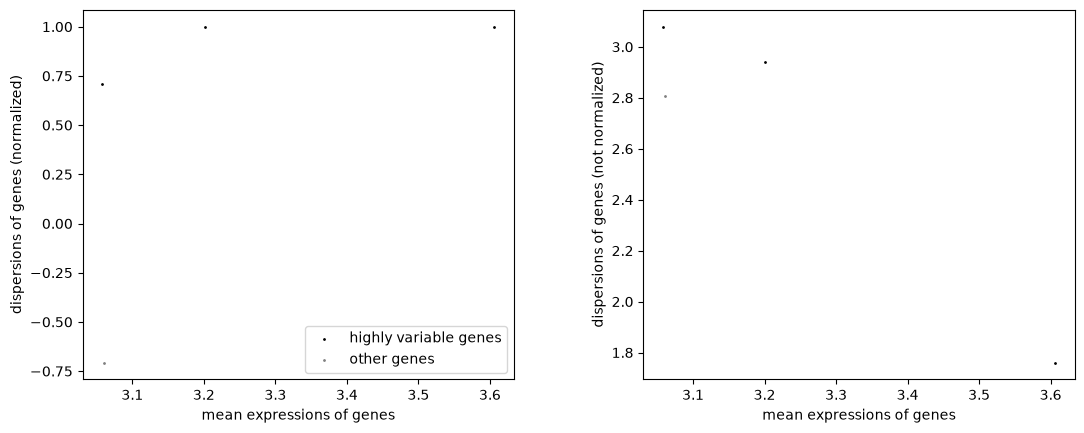

In [69]:
sc.pl.highly_variable_genes(adata_hvg)

In [70]:
sc.tl.pca(adata_hvg)

In [71]:
adata_hvg.obsm["X_pca"]

array([[ 2.5066597 , -0.7637239 ],
       [-2.8003304 , -0.54625446],
       [ 0.29367113,  1.3099787 ]], dtype=float32)

In [72]:
print(adata_hvg.obsm["X_pca"])

[[ 2.5066597  -0.7637239 ]
 [-2.8003304  -0.54625446]
 [ 0.29367113  1.3099787 ]]


In [73]:
sc.tl.pca(adata_hvg)

In [74]:
adata_hvg.obsm["X_pca"]

array([[ 2.5066597 , -0.7637239 ],
       [-2.8003304 , -0.54625446],
       [ 0.29367113,  1.3099787 ]], dtype=float32)

In [75]:
print(adata_hvg.obsm["X_pca"])

[[ 2.5066597  -0.7637239 ]
 [-2.8003304  -0.54625446]
 [ 0.29367113  1.3099787 ]]


In [76]:
print(adata_hvg.obsm["X_pca"].shape)

(3, 2)


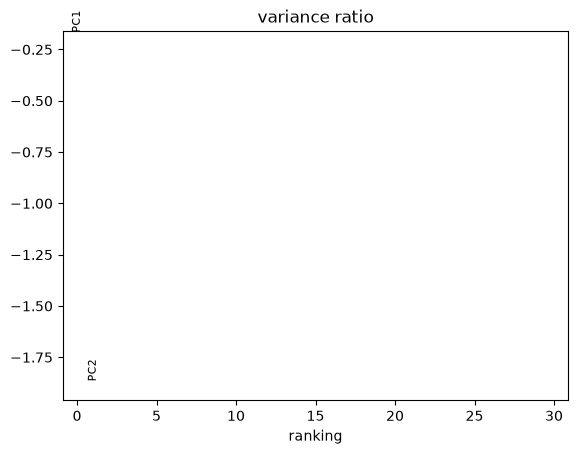

In [77]:
sc.pl.pca_variance_ratio(
    adata_hvg,
    log=True
)

In [78]:
sc.pp.neighbors(
    adata_hvg,
    n_neighbors=2,
    n_pcs=2
)

C:\Users\ADMIN\miniconda3\envs\blastoid\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [80]:
print(adata_hvg.obsp["distances"].toarray())

[[0.         0.         4.4604702 ]
 [0.         0.         5.09813309]
 [4.4604702  0.         0.        ]]


In [81]:
print(adata_hvg.obsp["connectivities"].toarray())

[[0. 0. 1.]
 [0. 0. 1.]
 [1. 1. 0.]]


In [82]:
sc.tl.umap(adata_hvg)

C:\Users\ADMIN\miniconda3\envs\blastoid\Lib\site-packages\umap\spectral.py:519: RuntimeWarning: k >= N for N * N square matrix. Attempting to use scipy.linalg.eigh instead.
  eigenvalues, eigenvectors = scipy.sparse.linalg.eigsh(


TypeError: Cannot use scipy.linalg.eigh for sparse A with k >= N. Use scipy.linalg.eigh(A.toarray()) or reduce k.

In [83]:
sc.pl.umap(adata_hvg)

KeyError: "Could not find 'umap' or 'X_umap' in .obsm"

In [84]:
adata_hvg.write("data/processed/toy_pca_neighbors.h5ad")

FileNotFoundError: [Errno 2] Unable to synchronously create file (unable to open file: name = 'data\processed\toy_pca_neighbors.h5ad', errno = 2, error message = 'No such file or directory', flags = 13, o_flags = 302)